In [ ]:
from scipy.special import gammaln
from scipy.special import factorial
from math import log as mathlog # why not use np.log ?
import numpy as np
import matplotlib.pyplot as plt
from week05 import make_microstate_factory
import numpy as np
from collections import Counter
from scipy.special import xlogy          # xlogy(x, y) = x*log(y), and 0 when x = 0
from scipy.optimize import minimize_scalar


# Counting microstates


In [82]:
N_cov = 12
N_vdW = 8
N_atomic = 16

In [83]:
MicroState = make_microstate_factory(N=2, L=3)    # N atoms, LxL lattice, B=0 (no second region)

In [84]:
MicroState = make_microstate_factory(N=2, L=3)    # N atoms, LxL lattice, B=0 (no second region)

print(MicroState.total)   # 36 = C(9,2)

36


In [85]:
s = MicroState(0)
print(s)            # index, energy, etc.
print(s.pos)        # coordinates of the two atoms
print(s.energy)     # -0.5, -0.25 or 0
print(s.bonds)      # [number of covalent bonds, number of vdW bonds]

MicroState #0 of 36 with E=-0.5 for N=2 in LxL=3x3
[[0. 2.]
 [1. 2.]]
-0.5
[1, 0]


In [86]:
states = [MicroState(i) for i in range(MicroState.total)]
E = np.array([s.energy for s in states])

print(Counter(E))        # should show 12 at -0.5, 8 at -0.25, 16 at 0.0

# Uniform distribution
P = np.full(len(states), 1 / len(states))
print(P.sum(), (P * E).sum())    # 1.0 and -2/9

Counter({np.float64(-0.0): 16, np.float64(-0.5): 12, np.float64(-0.25): 8})
1.0 -0.22222222222222224


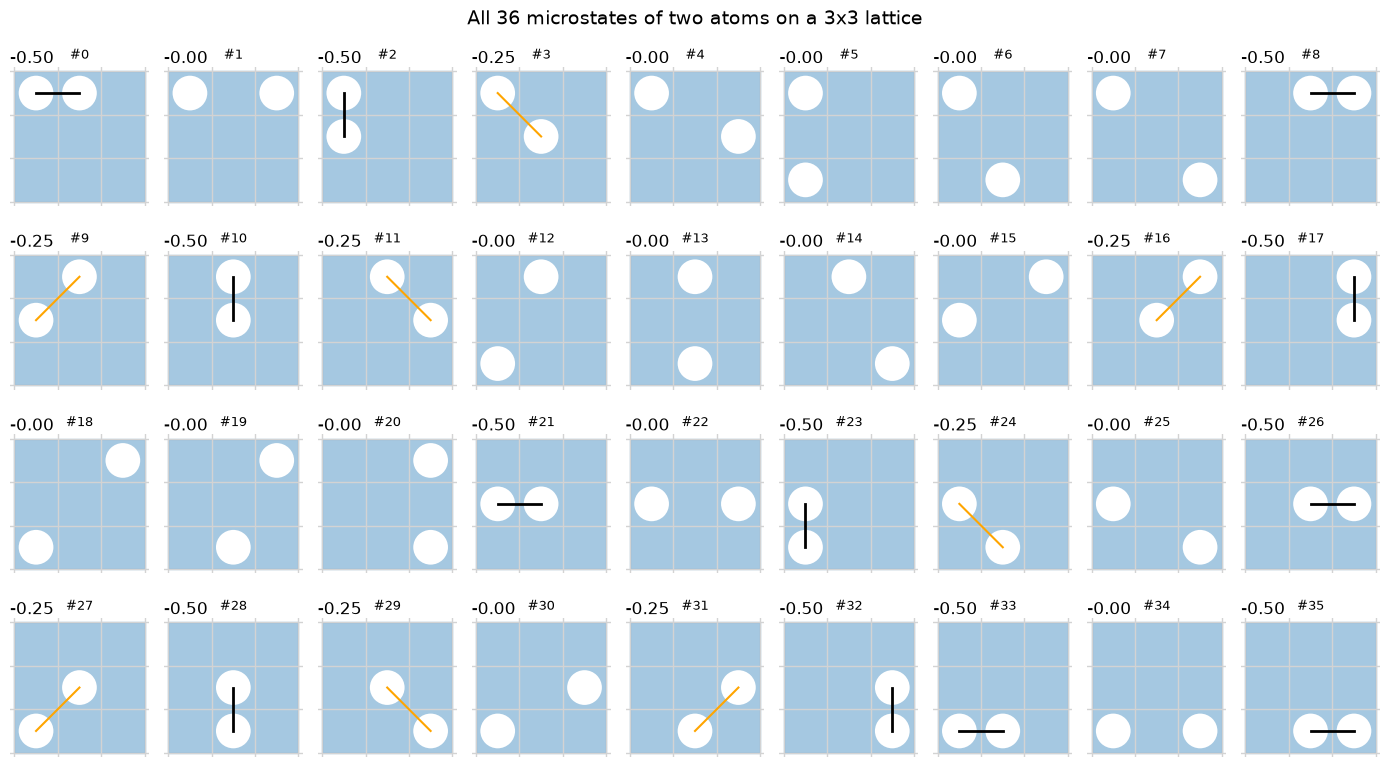

In [87]:
MicroState = make_microstate_factory(N=2, L=3)
states = [MicroState(i) for i in range(MicroState.total)]

fig, axes = plt.subplots(4, 9, figsize=(14, 8))

for ax, s in zip(axes.flat, states):
    s.plot(ax, label='Energy')           # energy shown above each lattice
    ax.set_title(f'#{s.i}', fontsize=9)

fig.suptitle('All 36 microstates of two atoms on a 3x3 lattice', fontsize=14)
plt.tight_layout()
plt.show()

In [88]:
states = [MicroState(i) for i in range(MicroState.total)]
E = np.array([s.energy for s in states])
P = np.where(E == -0.25, 1/8, 0.0)

print(P.sum())        # 1.0
print((P * E).sum())  # -0.25

1.0
-0.25


In [89]:
E = np.array([s.energy for s in states])
P = np.select([E == -0.5, E == -0.25, E == 0.0], [1/24, 0.0, 1/32])

print(P.sum())        # 1.0
print((P * E).sum())  # -0.25

0.9999999999999999
-0.25


In [90]:
E = np.array([s.energy for s in states])

beta = 2 * np.log(4/3)
w = np.exp(-beta * E)
Z = w.sum()
P = w / Z

print(Z, 32 + 16/np.sqrt(3))   # both ~41.238
print(P.sum())                 # 1.0
print((P * E).sum())           # -0.25

41.23760430703401 41.23760430703401
1.0
-0.24999999999999997


In [91]:
import numpy as np

MicroState = make_microstate_factory(N=2, L=3)
states = [MicroState(i) for i in range(MicroState.total)]
E = np.array([s.energy for s in states])

def entropy(P):
    p = P[P > 0]                      # P = 0 states contribute 0, eq. (22)
    return -(p * np.log(p)).sum()

beta = 2 * np.log(4/3)
w = np.exp(-beta * E)

dists = {
    "1: vdW only":        np.where(E == -0.25, 1/8, 0.0),
    "2: cov + separate":  np.select([E == -0.5, E == -0.25, E == 0.0], [1/24, 0, 1/32]),
    "3: Boltzmann":       w / w.sum(),
}

for name, P in dists.items():
    print(f"{name:20s} sum P = {P.sum():.4f}  <E> = {(P*E).sum():.4f}  S/kB = {entropy(P):.4f}")

1: vdW only          sum P = 1.0000  <E> = -0.2500  S/kB = 2.0794
2: cov + separate    sum P = 1.0000  <E> = -0.2500  S/kB = 3.3219
3: Boltzmann         sum P = 1.0000  <E> = -0.2500  S/kB = 3.5755


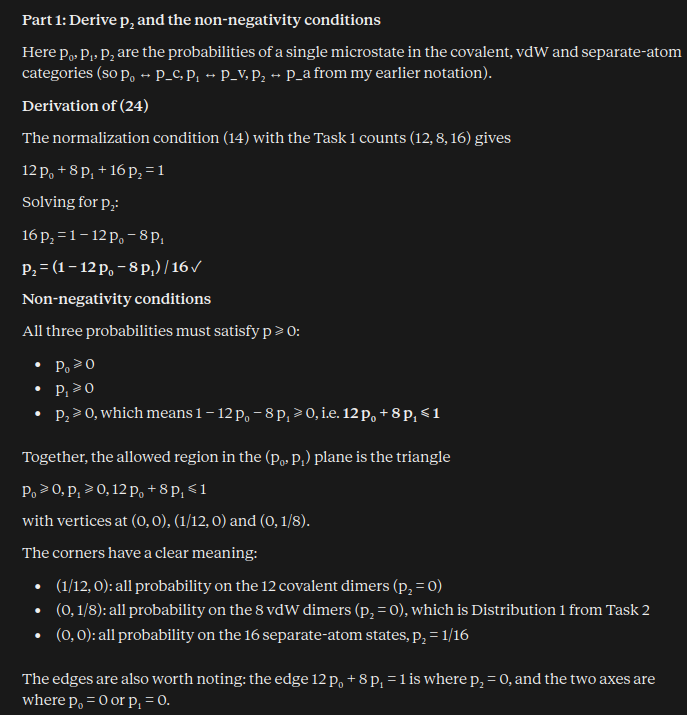

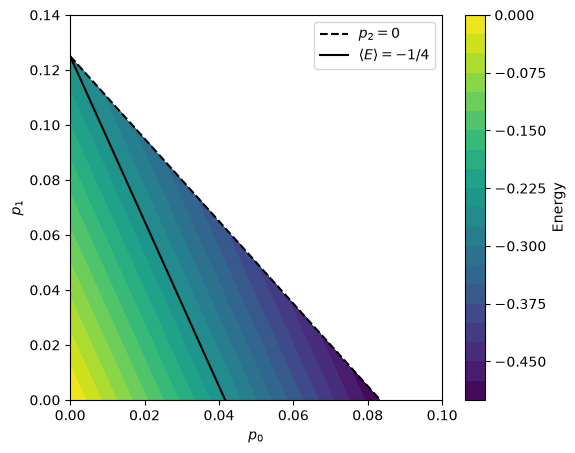

In [92]:
p0, p1 = np.meshgrid(np.linspace(0, 0.10, 400), np.linspace(0, 0.14, 400))
p2 = (1 - 12*p0 - 8*p1) / 16
E = -6*p0 - 2*p1

# Mask out the disallowed region (p2 < 0)
E = np.ma.masked_where(p2 < 0, E)

fig, ax = plt.subplots(figsize=(6, 5))
cf = ax.contourf(p0, p1, E, levels=20, cmap='viridis')
fig.colorbar(cf, label='Energy')

# Boundary p2 = 0 (dashed)
x = np.linspace(0, 1/12, 100)
ax.plot(x, 1/8 - 1.5*x, 'k--', label=r'$p_2 = 0$')

# <E> = -1/4 contour (solid)
x = np.linspace(0, 1/24, 100)
ax.plot(x, 1/8 - 3*x, 'k-', label=r'$\langle E\rangle=-1/4$')

ax.set_xlabel('$p_0$')
ax.set_ylabel('$p_1$')
ax.set_xlim(0, 0.10)
ax.set_ylim(0, 0.14)
ax.legend()
plt.show()

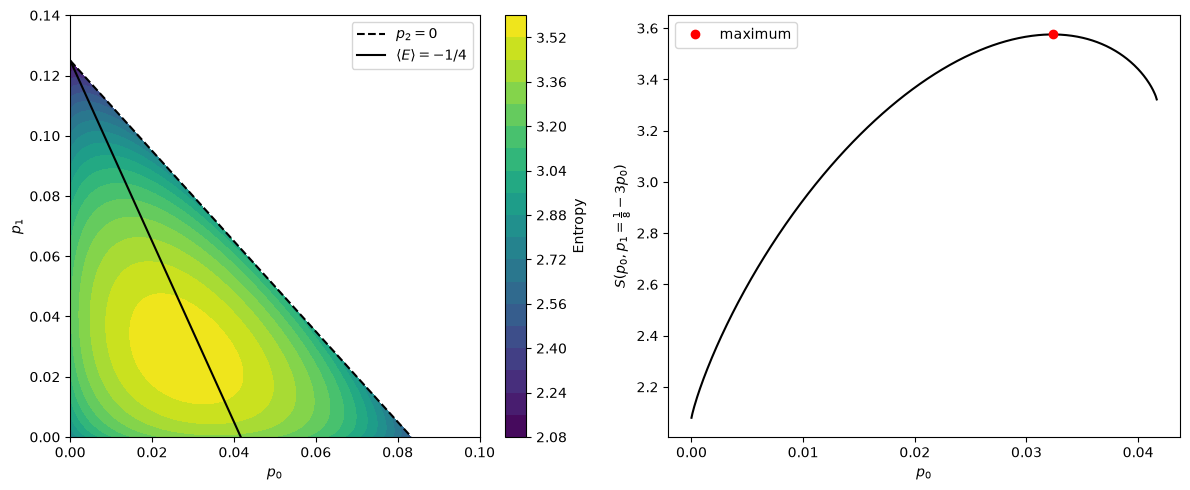

0.03233294842750851 3.575509529747472


In [93]:

def entropy(p0, p1):
    p2 = (1 - 12*p0 - 8*p1) / 16
    p2 = np.clip(p2, 0, None)            # avoid log of tiny negatives; masked later
    return -(12*xlogy(p0, p0) + 8*xlogy(p1, p1) + 16*xlogy(p2, p2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# ---- Left: entropy over the allowed region ----
p0, p1 = np.meshgrid(np.linspace(0, 0.10, 400), np.linspace(0, 0.14, 400))
p2 = (1 - 12*p0 - 8*p1) / 16
S = np.ma.masked_where(p2 < 0, entropy(p0, p1))

cf = ax1.contourf(p0, p1, S, levels=20, cmap='viridis')
fig.colorbar(cf, ax=ax1, label='Entropy')

x = np.linspace(0, 1/12, 100)
ax1.plot(x, 1/8 - 1.5*x, 'k--', label=r'$p_2=0$')          # boundary
x = np.linspace(0, 1/24, 100)
ax1.plot(x, 1/8 - 3*x, 'k-', label=r'$\langle E\rangle=-1/4$')  # eq. (26)
ax1.set_xlim(0, 0.10); ax1.set_ylim(0, 0.14)
ax1.set_xlabel('$p_0$'); ax1.set_ylabel('$p_1$')
ax1.legend()

# ---- Right: entropy along the constant-energy line ----
p0_line = np.linspace(0, 1/24, 500)
S_line = entropy(p0_line, 1/8 - 3*p0_line)
ax2.plot(p0_line, S_line, 'k-')

p0_max = 1 / (24 + 4*np.sqrt(3))
ax2.plot(p0_max, entropy(p0_max, 1/8 - 3*p0_max), 'ro', label='maximum')
ax2.set_xlabel('$p_0$')
ax2.set_ylabel(r'$S(p_0, p_1=\frac{1}{8}-3p_0)$')
ax2.legend()

plt.tight_layout()
plt.show()

print(p0_max, entropy(p0_max, 1/8 - 3*p0_max))   # ~0.0323, ~3.5755

p0 = 0.03233, p1 = 0.02800, S/kB = 3.57551


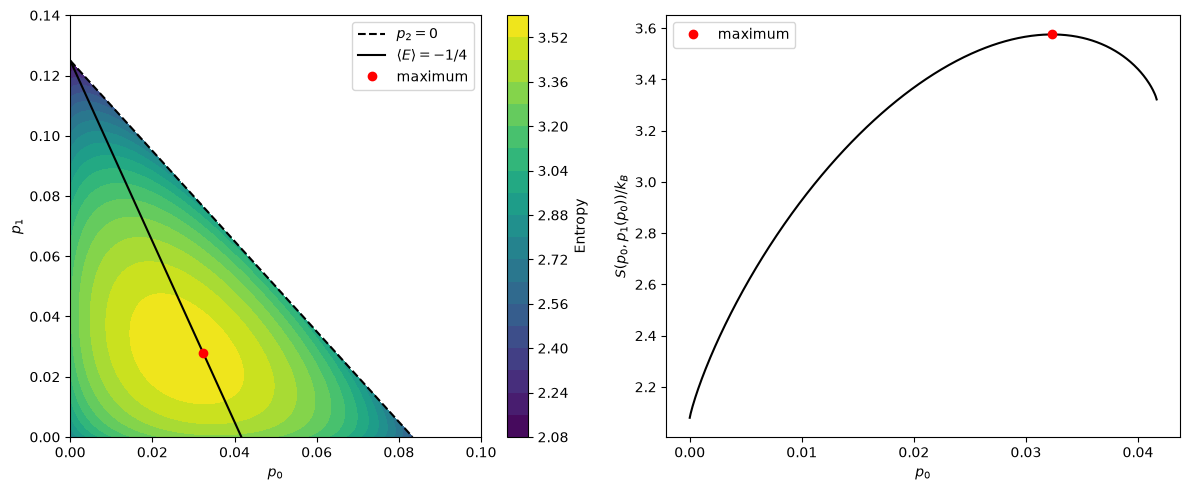

In [94]:
def entropy(p0, p1):
    p2 = np.clip((1 - 12*p0 - 8*p1) / 16, 0, None)
    return -(12*xlogy(p0, p0) + 8*xlogy(p1, p1) + 16*xlogy(p2, p2))

def p1_of_p0(p0):                       # eq. (28)
    return 1/8 - 3*p0

def S_line(p0):                         # S/kB restricted to the line
    return entropy(p0, p1_of_p0(p0))

# ---- 1D numerical maximisation: minimise -S on 0 <= p0 <= 1/24 ----
res = minimize_scalar(lambda p: -S_line(p), bounds=(0, 1/24), method='bounded',
                      options={'xatol': 1e-12})
p0_max = res.x
p1_max = p1_of_p0(p0_max)
S_max = -res.fun
print(f"p0 = {p0_max:.5f}, p1 = {p1_max:.5f}, S/kB = {S_max:.5f}")
# analytic check: p0 = 1/(24+4*sqrt(3)) ~ 0.03233, S/kB ~ 3.5755

# ---- Plot ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left: entropy contour
p0, p1 = np.meshgrid(np.linspace(0, 0.10, 400), np.linspace(0, 0.14, 400))
p2 = (1 - 12*p0 - 8*p1) / 16
S = np.ma.masked_where(p2 < 0, entropy(p0, p1))
cf = ax1.contourf(p0, p1, S, levels=20, cmap='viridis')
fig.colorbar(cf, ax=ax1, label='Entropy')

x = np.linspace(0, 1/12, 100)
ax1.plot(x, 1/8 - 1.5*x, 'k--', label=r'$p_2=0$')
x = np.linspace(0, 1/24, 100)
ax1.plot(x, p1_of_p0(x), 'k-', label=r'$\langle E\rangle=-1/4$')
ax1.plot(p0_max, p1_max, 'ro', label='maximum')          # mark in left panel
ax1.set_xlim(0, 0.10); ax1.set_ylim(0, 0.14)
ax1.set_xlabel('$p_0$'); ax1.set_ylabel('$p_1$')
ax1.legend()

# Right: S along the line
x = np.linspace(0, 1/24, 500)
ax2.plot(x, S_line(x), 'k-')
ax2.plot(p0_max, S_max, 'ro', label='maximum')           # mark in right panel
ax2.set_xlabel('$p_0$')
ax2.set_ylabel(r'$S(p_0, p_1(p_0))/k_B$')
ax2.legend()

plt.tight_layout()
plt.show()

In [95]:
Z = 32 + 16/np.sqrt(3)
boltz = np.array([4/3, 2/np.sqrt(3), 1]) / Z
opt   = np.array([p0_max, p1_max, (1 - 12*p0_max - 8*p1_max)/16])

print(boltz)                       # [0.032333 0.028001 0.024250]
print(opt)                         # same to ~1e-8
print(np.allclose(boltz, opt, atol=1e-6))
print(S_max, entropy(*boltz[:2]))  # both ~3.5755

[0.03233295 0.02800115 0.02424971]
[0.03233295 0.02800115 0.02424971]
True
3.575509529747472 3.575509529747472


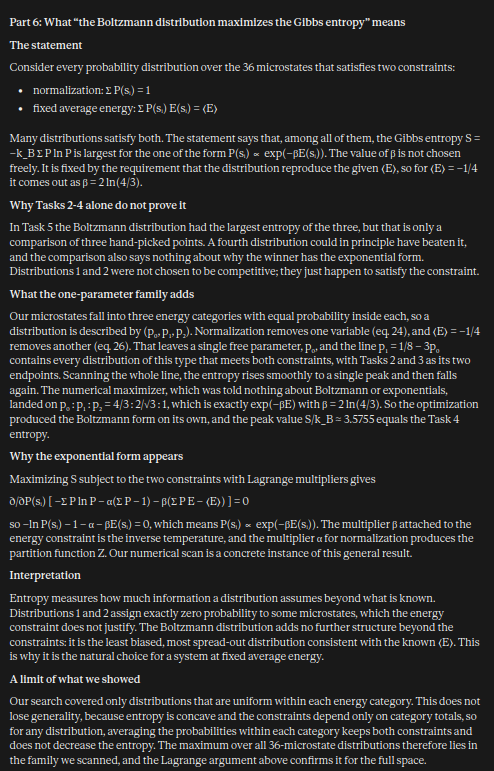